# Exploratory Data Analysis: Retail Sales

**Objective:** uncover sales patterns, customer behaviour trends and actionable business insights.
**Stack:** Python · pandas · matplotlib · seaborn
**Data:** Kaggle *Retail Sales Dataset* (`retail_sales_dataset.csv`): 1,000 transactions, Jan 2023 – 1 Jan 2024.

| Column | Meaning |
|---|---|
| Transaction ID | unique order |
| Date | purchase date |
| Customer ID / Gender / Age | customer attributes |
| Product Category | Beauty, Clothing or Electronics |
| Quantity / Price per Unit / Total Amount | units, unit price, revenue |

**Dataset limitations that shape this analysis**
- There is **no product-name column**, so "products" are defined as *category @ price point* (e.g. "Clothing @ $300").
- Every `Customer ID` appears **once**, so repeat-purchase analysis is not possible.
- The data covers **one year**, so seasonality cannot be separated from noise. 1 Jan 2024 is a single day and is excluded from time-series charts.

**Contents:** 1 Load & inspect · 2 Cleaning · 3 Descriptive stats · 4 Time series · 5 Demographics · 6 Products · 7 Correlation · 8 Extra insights · 9 Conclusions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import warnings, os
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='deep', font_scale=1.0)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['figure.figsize'] = (10, 4.5)
money = mtick.FuncFormatter(lambda x, _: f'${x:,.0f}')

## 1. Load the dataset & initial inspection

In [2]:
df = pd.read_csv('retail_sales_dataset.csv')
# The file has no product-name column, so define a product as category @ price point
df['Product Name'] = df['Product Category'] + ' @ $' + df['Price per Unit'].astype(str)
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount,Product Name
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150,Beauty @ $50
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000,Clothing @ $500
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30,Electronics @ $30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500,Clothing @ $500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100,Beauty @ $50


In [3]:
print('Shape:', df.shape)
print('\nColumn dtypes:'); print(df.dtypes)
print('\nNull values per column:'); print(df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())

Shape: (1000, 10)

Column dtypes:
Transaction ID      int64
Date                  str
Customer ID           str
Gender                str
Age                 int64
Product Category      str
Quantity            int64
Price per Unit      int64
Total Amount        int64
Product Name          str
dtype: object

Null values per column:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
Product Name        0
dtype: int64

Duplicate rows: 0


### Observations
- The dataset has **1,000 transactions × 9 columns** (10 after the derived product label), spanning 1 Jan 2023 – 1 Jan 2024. `Date` is stored as text and is converted in Section 2.
- It is **clean**: no null values, no duplicate rows, and `Total Amount` equals `Quantity × Price per Unit` on every row.
- Two structural limits matter: there is **no product-name column** (so I define a product as *category @ price point*), and all **1,000 Customer IDs are unique**, so each customer bought exactly once and repeat-purchase analysis is impossible.

## 2. Cleaning & feature engineering

In [4]:
df['Date'] = pd.to_datetime(df['Date'])

# Impute the few missing ages with the median (robust to outliers)
n_missing = df['Age'].isnull().sum()
df['Age'] = df['Age'].fillna(df['Age'].median())

# Sanity check: Total Amount should equal Quantity x Price
mismatch = (np.abs(df['Quantity'] * df['Price per Unit'] - df['Total Amount']) > 0.01).sum()
print(f'Imputed {n_missing} missing ages | rows where Qty x Price != Total: {mismatch}')

df['Year']      = df['Date'].dt.year
df['Month']     = df['Date'].dt.month
df['Quarter']   = df['Date'].dt.to_period('Q')
df['Weekday']   = df['Date'].dt.day_name()
df['AgeGroup']  = pd.cut(df['Age'], bins=[17, 24, 34, 44, 54, 100],
                         labels=['18-24', '25-34', '35-44', '45-54', '55+'])
print(f"Date range: {df['Date'].min().date()} -> {df['Date'].max().date()}")
# 1 Jan 2024 is a single day: exclude from monthly/quarterly trend charts
ts = df[df['Date'] < '2024-01-01']
print(f'Rows used for trends: {len(ts)} of {len(df)}')

Imputed 0 missing ages | rows where Qty x Price != Total: 0
Date range: 2023-01-01 -> 2024-01-01
Rows used for trends: 998 of 1000


## 3. Descriptive statistics

In [5]:
num_cols = ['Age', 'Quantity', 'Price per Unit', 'Total Amount']
stats = pd.DataFrame({
    'mean':   df[num_cols].mean(),
    'median': df[num_cols].median(),
    'mode':   df[num_cols].mode().iloc[0],
    'std':    df[num_cols].std(),
    'min':    df[num_cols].min(),
    'max':    df[num_cols].max(),
}).round(2)
stats

,mean,median,mode,std,min,max
Age,41.39,42.0,43.0,13.68,18,64
Quantity,2.51,3.0,4.0,1.13,1,4
Price per Unit,179.89,50.0,50.0,189.68,25,500
Total Amount,456.00,135.0,50.0,560.00,25,2000


### Observations
- **Order value is heavily right-skewed:** mean $456 vs median $135. A minority of large orders (max $2,000) pulls the average up, so the median is the better "typical order" figure.
- `Price per Unit` takes only **five values ($25, $30, $50, $300, $500)**, each on roughly 18–21% of orders. The mean ($180) is far above the median ($50) because of the two premium price points.
- Quantity is 1–4 (median 3, mode 4), so order value is driven much more by unit price than by basket size.
- Age spans 18–64 with mean 41.4 and median 42, close to a uniform spread rather than a bell shape.

## 4. Time series analysis

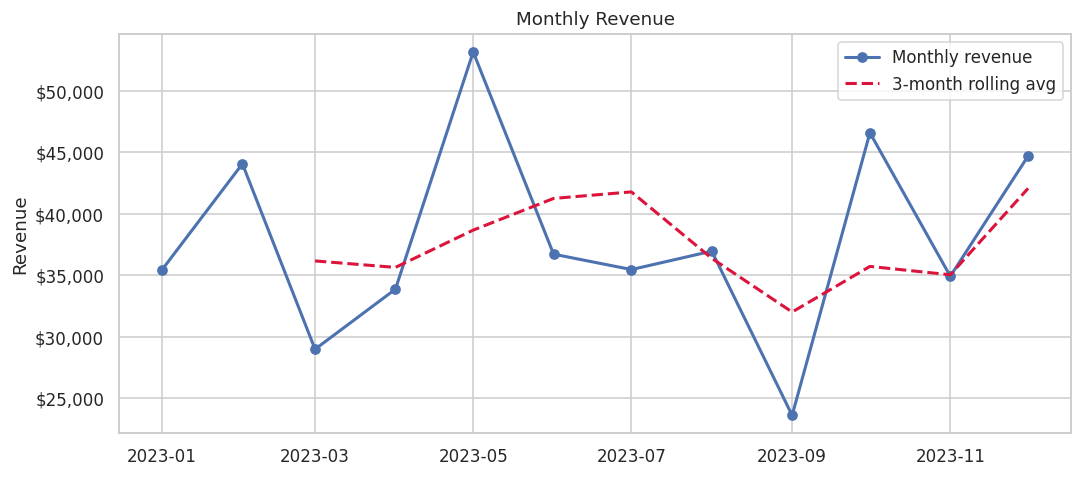

Peak month: May 2023 ($53,150) | Lowest: Sep 2023 ($23,620)


In [6]:
monthly = ts.set_index('Date')['Total Amount'].resample('MS').sum()

fig, ax = plt.subplots()
ax.plot(monthly.index, monthly.values, marker='o', lw=2, label='Monthly revenue')
ax.plot(monthly.index, monthly.rolling(3).mean(), ls='--', lw=2, color='crimson', label='3-month rolling avg')
ax.yaxis.set_major_formatter(money)
ax.set(title='Monthly Revenue', xlabel='', ylabel='Revenue')
ax.legend()
plt.tight_layout(); plt.show()

peak = monthly.idxmax(); low = monthly.idxmin()
print(f"Peak month: {peak:%b %Y} (${monthly.max():,.0f}) | Lowest: {low:%b %Y} (${monthly.min():,.0f})")

### Observations
- Monthly revenue is **volatile with no clear holiday pattern**: May is the peak ($53.2k) and September the trough ($23.6k), more than a 2× swing. Feb, Oct and Dec form secondary highs ($44–47k).
- Unlike typical retail data there is no strong Q4 build-up: November ($34.9k) is below average.
- With only 1,000 orders, a handful of $500 orders can move a month by thousands of dollars, so some of this variation is noise. The 3-month average (dashed) shows a roughly flat trend across the year.
- Two orders from 1 Jan 2024 are excluded as a partial month.

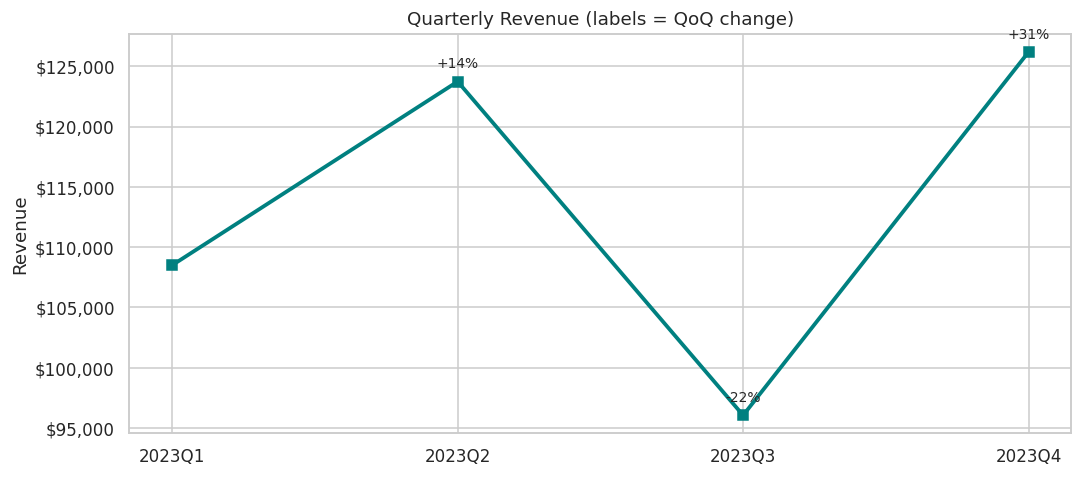

Quarter
2023Q1    $108,500
2023Q2    $123,735
2023Q3     $96,045
2023Q4    $126,190
Freq: Q-DEC


In [7]:
quarterly = ts.groupby('Quarter')['Total Amount'].sum()
qgrowth = quarterly.pct_change() * 100

fig, ax = plt.subplots()
ax.plot(quarterly.index.astype(str), quarterly.values, marker='s', lw=2.5, color='teal')
for x, y, g in zip(quarterly.index.astype(str), quarterly.values, qgrowth):
    ax.annotate('' if np.isnan(g) else f'{g:+.0f}%', (x, y), textcoords='offset points', xytext=(0, 9), ha='center', fontsize=9)
ax.yaxis.set_major_formatter(money)
ax.set(title='Quarterly Revenue (labels = QoQ change)', ylabel='Revenue')
plt.tight_layout(); plt.show()

print(quarterly.map('${:,.0f}'.format).to_string())

### Observations
- **Q4 is the best quarter ($126.2k)**, narrowly ahead of Q2 ($123.7k). **Q3 is the weakest ($96.0k), −22% vs Q2**, driven mainly by September.
- Q4 rebounds by **+31%** from Q3, but overall there is no sustained growth: Q4 is only 16% above Q1.
- Revenue per quarter is $96k–$126k, so the business is steady with a recurring mid-year dip worth investigating. A second year of data is needed to confirm whether it is seasonal.

## 5. Customer demographics

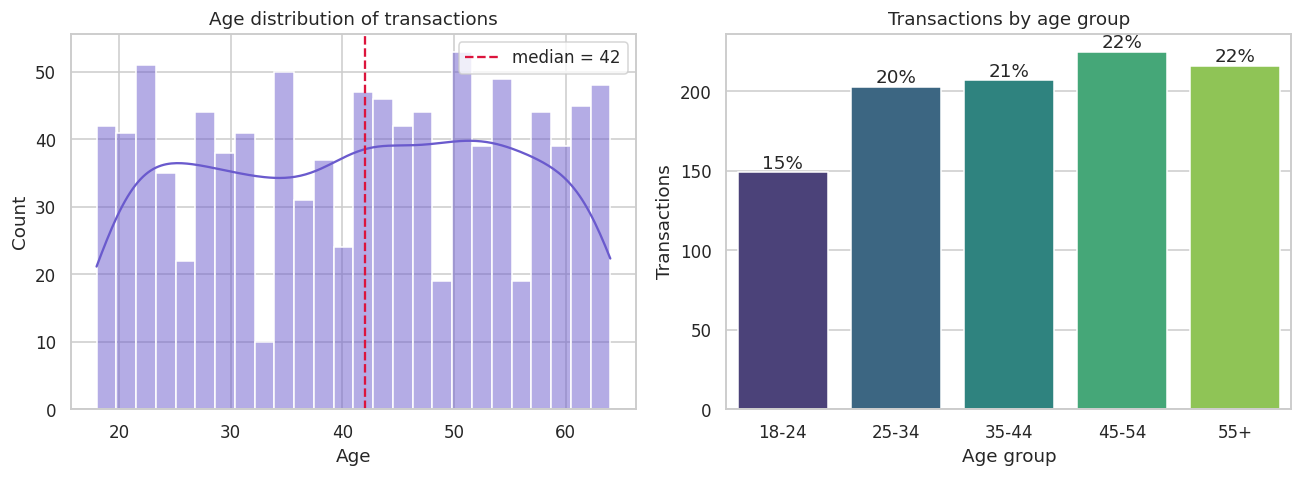

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(df['Age'], bins=26, kde=True, ax=axes[0], color='slateblue')
axes[0].axvline(df['Age'].median(), color='crimson', ls='--', label=f"median = {df['Age'].median():.0f}")
axes[0].legend(); axes[0].set_title('Age distribution of transactions')

ag = df['AgeGroup'].value_counts().sort_index()
sns.barplot(x=ag.index, y=ag.values, ax=axes[1], palette='viridis')
for i, v in enumerate(ag.values):
    axes[1].text(i, v, f'{v / ag.sum():.0%}', ha='center', va='bottom')
axes[1].set(title='Transactions by age group', xlabel='Age group', ylabel='Transactions')
plt.tight_layout(); plt.show()

### Observations
- Customers are **spread fairly evenly across age groups**: 35–44, 45–54 and 55+ each account for 21–23% of transactions, 25–34 for 20%, and 18–24 for 15%.
- 18–24 is the smallest group partly because it covers only 7 years of age versus 10 for the others. Per year of age, young adults are not under-represented.
- The age histogram is flat and the median age is 42, so this is not a young-skewed customer base; marketing should not assume one.

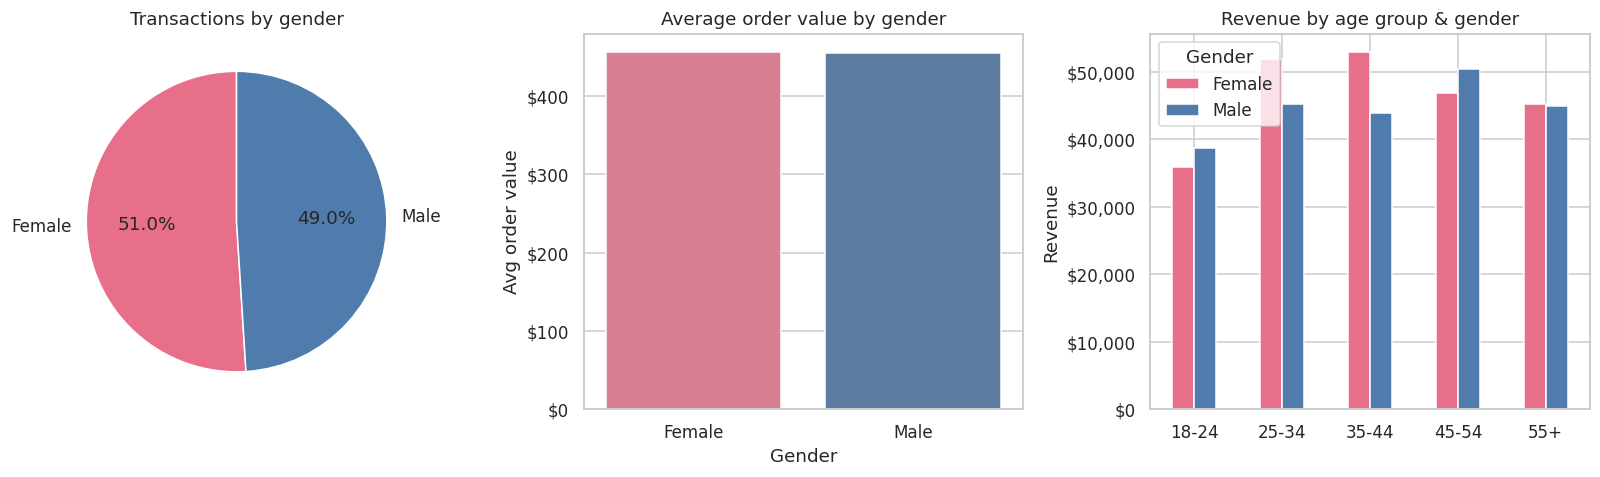

           sum    mean
Gender                
Female  232840  456.55
Male    223160  455.43

Average order value by age group:
AgeGroup
18-24    501.0
25-34    478.0
35-44    468.0
45-54    432.0
55+      418.0


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

g = df['Gender'].value_counts()
axes[0].pie(g, labels=g.index, autopct='%1.1f%%', startangle=90, colors=['#e76f8a', '#4f7cac'])
axes[0].set_title('Transactions by gender')

rev_g = df.groupby('Gender')['Total Amount'].agg(['sum', 'mean'])
sns.barplot(x=rev_g.index, y=rev_g['mean'], ax=axes[1], palette=['#e76f8a', '#4f7cac'])
axes[1].set(title='Average order value by gender', ylabel='Avg order value'); axes[1].yaxis.set_major_formatter(money)

gx = df.pivot_table(index='AgeGroup', columns='Gender', values='Total Amount', aggfunc='sum')
gx.plot(kind='bar', ax=axes[2], color=['#e76f8a', '#4f7cac'], rot=0)
axes[2].set(title='Revenue by age group & gender', xlabel='', ylabel='Revenue'); axes[2].yaxis.set_major_formatter(money)
plt.tight_layout(); plt.show()
print(rev_g.round(2))
print('\nAverage order value by age group:'); print(df.groupby('AgeGroup')['Total Amount'].mean().round(0).to_string())

### Observations
- The gender split is almost even: **51% women, 49% men**, and revenue follows ($232.8k vs $223.2k).
- **Average order value is virtually identical** ($456.55 vs $455.43), so gender alone does not distinguish high and low spenders.
- Age tells a different story: **average order value falls steadily with age, from $501 (18–24) to $418 (55+)**, about 17% lower. Younger customers spend more per order even though they are the smallest group by volume.

## 6. Product analysis

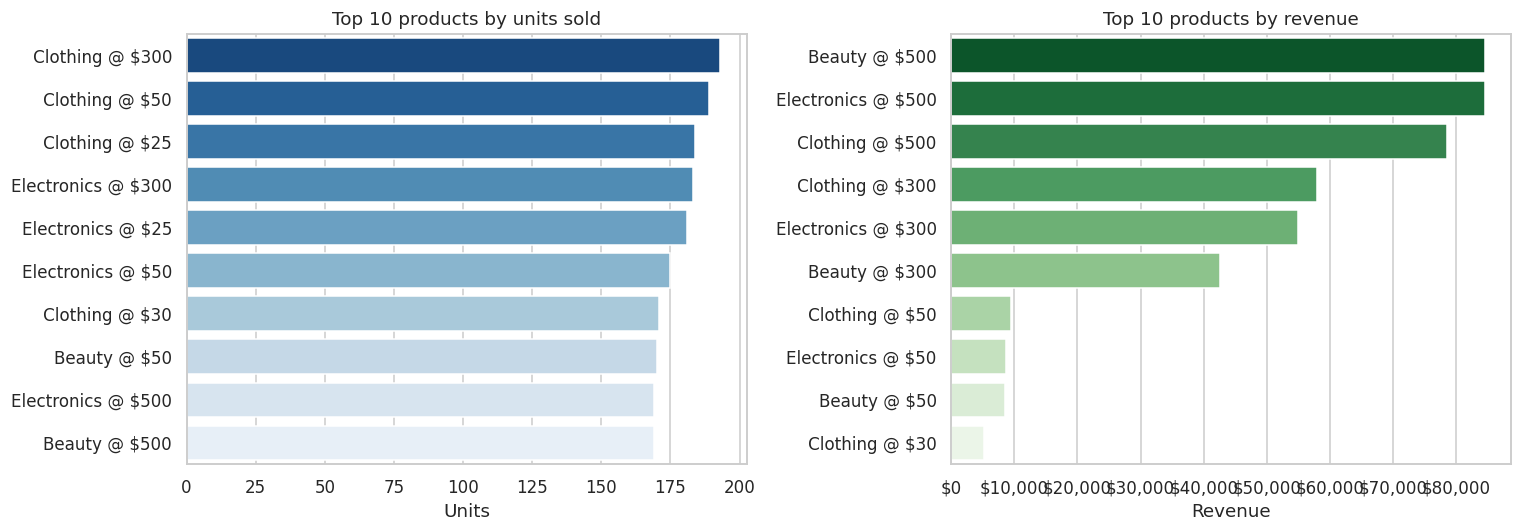

In both top-10 lists: 8 | only top-10 by units: ['Clothing @ $25', 'Electronics @ $25']
Only top-10 by revenue: ['Beauty @ $300', 'Clothing @ $500']


In [10]:
prod = df.groupby('Product Name').agg(units=('Quantity', 'sum'), revenue=('Total Amount', 'sum'),
                                      category=('Product Category', 'first'))
top_units = prod.sort_values('units', ascending=False).head(10)
top_rev = prod.sort_values('revenue', ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=top_units['units'], y=top_units.index, ax=axes[0], palette='Blues_r')
axes[0].set(title='Top 10 products by units sold', xlabel='Units', ylabel='')
sns.barplot(x=top_rev['revenue'], y=top_rev.index, ax=axes[1], palette='Greens_r')
axes[1].set(title='Top 10 products by revenue', xlabel='Revenue', ylabel=''); axes[1].xaxis.set_major_formatter(money)
plt.tight_layout(); plt.show()

both = set(top_units.index) & set(top_rev.index)
print('In both top-10 lists:', len(both), '| only top-10 by units:', sorted(set(top_units.index) - both))
print('Only top-10 by revenue:', sorted(set(top_rev.index) - both))

### Observations
- Because the dataset has no product names, products are defined as **category @ price point** (15 combinations).
- By units, the top 10 are very close together (169–193 units each), with Clothing @ $300, Clothing @ $50 and Clothing @ $25 on top. No single product dominates volume.
- By revenue the picture is very different: the top six are all **$500 or $300 items**, led by Beauty @ $500 and Electronics @ $500 ($84.5k each). Clothing @ $25 sold 184 units but earned only **$4.6k**, versus $57.9k for Clothing @ $300 with a similar 193 units.
- 8 of the 10 products appear on both lists. The two that appear only in the units list (Clothing @ $25, Electronics @ $25) are low-value volume; the two only in the revenue list (Beauty @ $300, Clothing @ $500) are high-value.

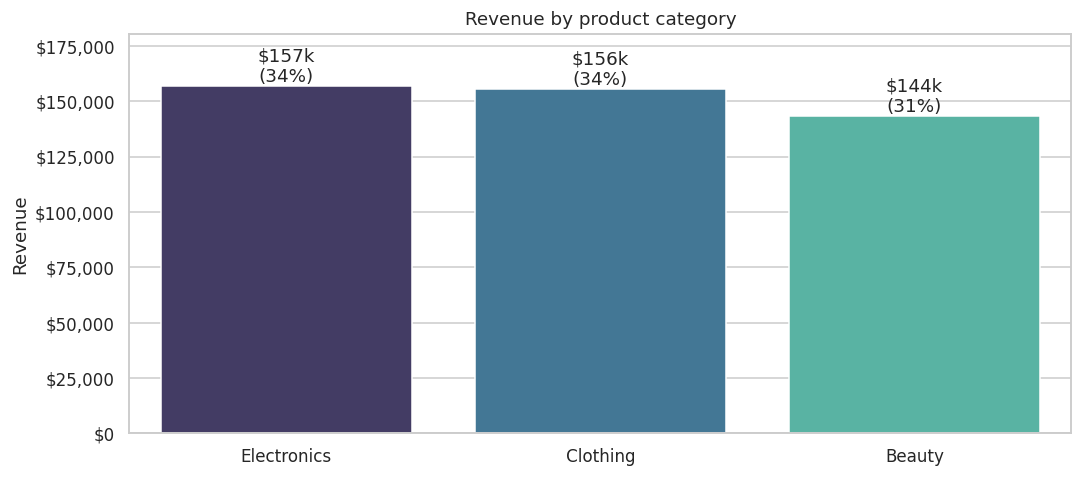

,revenue,orders,aov,share
Product Category,,,,
Electronics,156905,342,458.79,0.34
Clothing,155580,351,443.25,0.34
Beauty,143515,307,467.48,0.31


In [11]:
cat = df.groupby('Product Category').agg(revenue=('Total Amount', 'sum'), orders=('Transaction ID', 'count'),
                                        aov=('Total Amount', 'mean')).sort_values('revenue', ascending=False)
cat['share'] = cat['revenue'] / cat['revenue'].sum()

fig, ax = plt.subplots()
sns.barplot(x=cat.index, y=cat['revenue'], ax=ax, palette='mako')
for i, (r, s) in enumerate(zip(cat['revenue'], cat['share'])):
    ax.text(i, r, f'${r/1000:,.0f}k\n({s:.0%})', ha='center', va='bottom')
ax.yaxis.set_major_formatter(money); ax.set(title='Revenue by product category', xlabel='', ylabel='Revenue')
ax.set_ylim(0, cat['revenue'].max() * 1.15)
plt.tight_layout(); plt.show()
cat.round(2)

### Observations
- The three categories are **nearly equal in revenue**: Electronics $156.9k (34%), Clothing $155.6k (34%), Beauty $143.5k (31%).
- Clothing has the most orders (351) but the lowest average order value ($443). Beauty has the fewest orders (307) but the **highest average order value ($468)**.
- Category on its own is therefore not the main revenue lever. Price point matters far more (see Section 8b).

## 7. Correlation heatmap

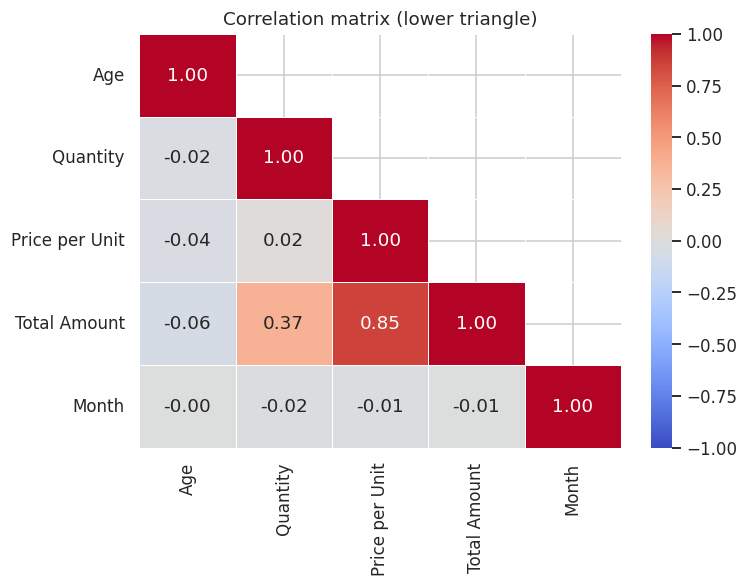

In [12]:
corr_cols = ['Age', 'Quantity', 'Price per Unit', 'Total Amount', 'Month']
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1,
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1), linewidths=.5, ax=ax)
ax.set_title('Correlation matrix (lower triangle)')
plt.tight_layout(); plt.show()

### Observations
- `Total Amount` is driven mainly by **Price per Unit (r = 0.85)**, with Quantity a weaker driver (r = 0.37).
- Price and Quantity are uncorrelated (0.02), so customers do not buy fewer units of expensive items. Premium products are not being held back by basket size.
- **Age has a small negative correlation with order value (−0.06)**, consistent with the falling average order value by age seen earlier. Month is ~0: order size does not vary by season.

## 8. Additional visualisations: non-obvious insights

### 8a. Who buys what? Category mix by age group (share of each group's revenue)

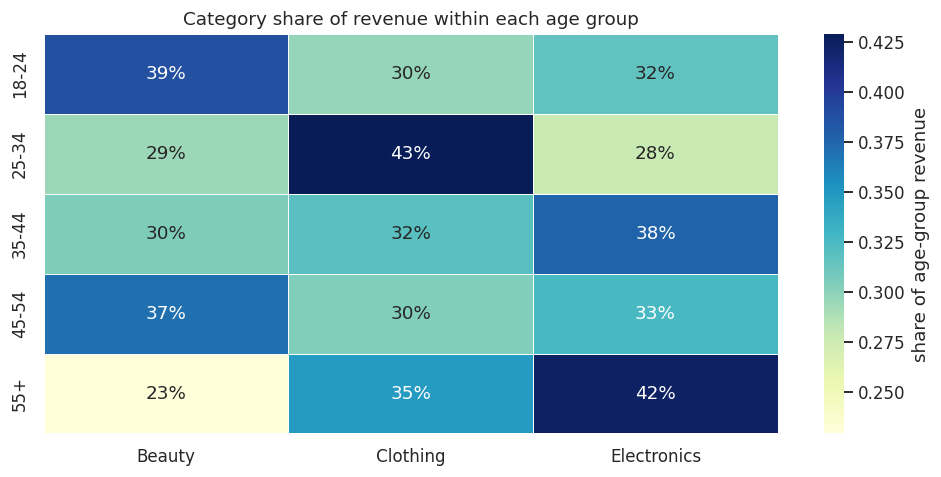

Product Category  Beauty  Clothing  Electronics
Gender                                         
Female              32.1      34.9         33.0
Male                30.8      33.3         35.9


In [13]:
mix = df.pivot_table(index='AgeGroup', columns='Product Category', values='Total Amount', aggfunc='sum')
mix_pct = mix.div(mix.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(mix_pct, annot=True, fmt='.0%', cmap='YlGnBu', linewidths=.5, ax=ax, cbar_kws={'label': 'share of age-group revenue'})
ax.set(title='Category share of revenue within each age group', xlabel='', ylabel='')
plt.tight_layout(); plt.show()

gmix = df.pivot_table(index='Gender', columns='Product Category', values='Total Amount', aggfunc='sum')
print((gmix.div(gmix.sum(axis=1), axis=0) * 100).round(1))

### Observations
- Category preference varies noticeably by age: **25–34 year-olds put 43% of their spend into Clothing**, **55+ put 42% into Electronics** (and only 23% into Beauty), while **18–24s favour Beauty (39%)**.
- Gender differences are small: women lean slightly to Clothing (34.9%), men to Electronics (35.9%). Age explains category choice better than gender does.
- Caveat: each age-group × category cell contains only ~50–75 orders, so treat these as directional hypotheses to test, not firm facts.

### 8b. Price tier: where does the revenue really come from? (plus the weekday effect)

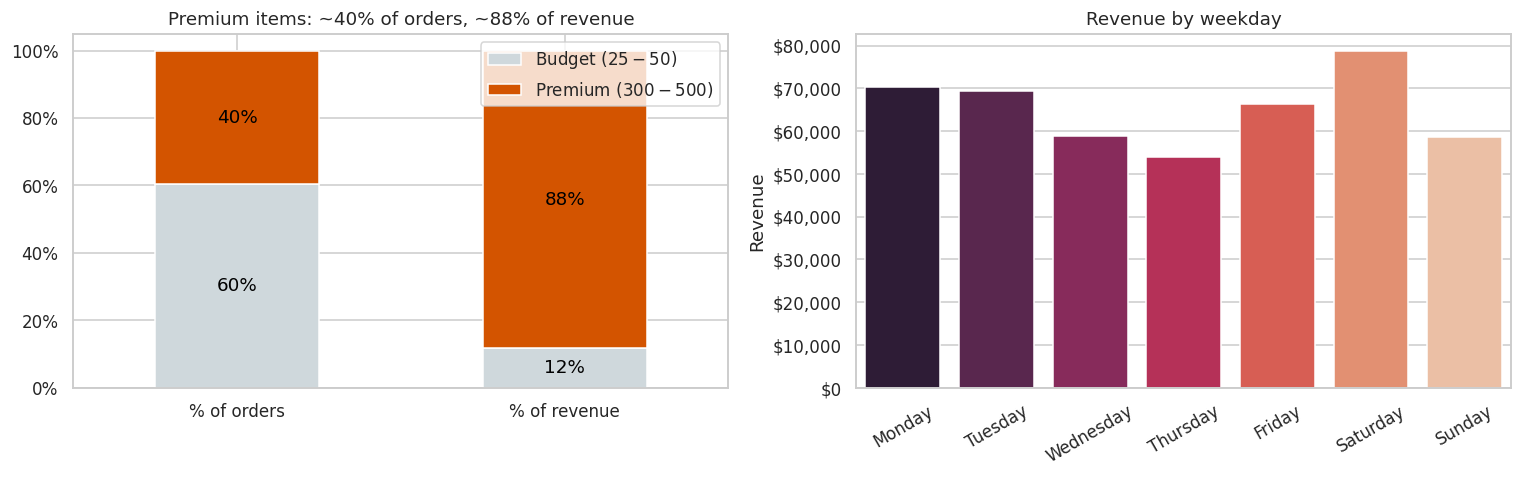

                     orders  revenue       aov  % of orders  % of revenue
Tier                                                                     
Budget ($25-$50)        604    53100    87.914        0.604         0.116
Premium ($300-$500)     396   402900  1017.424        0.396         0.884
Top 10% of orders = 38.2% of revenue | 30% of orders reach 80% of revenue
Weekend (Sat+Sun) share of revenue: 30.1% (even split would be 28.6%)


In [14]:
df['Tier'] = np.where(df['Price per Unit'] >= 300, 'Premium ($300-$500)', 'Budget ($25-$50)')
tier = df.groupby('Tier').agg(orders=('Transaction ID', 'count'), revenue=('Total Amount', 'sum'), aov=('Total Amount', 'mean'))
tier['% of orders'] = tier['orders'] / tier['orders'].sum()
tier['% of revenue'] = tier['revenue'] / tier['revenue'].sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
tier[['% of orders', '% of revenue']].T.plot(kind='bar', stacked=True, ax=axes[0], color=['#cfd8dc', '#d35400'], rot=0)
for c in axes[0].containers:
    axes[0].bar_label(c, labels=[f'{v.get_height():.0%}' for v in c], label_type='center', color='black')
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].set(title='Premium items: ~40% of orders, ~88% of revenue'); axes[0].legend(title='')

order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
wd = df.groupby('Weekday')['Total Amount'].agg(['sum', 'count']).reindex(order)
sns.barplot(x=wd.index, y=wd['sum'], ax=axes[1], palette='rocket')
axes[1].set(title='Revenue by weekday', xlabel='', ylabel='Revenue'); axes[1].yaxis.set_major_formatter(money)
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

print(tier.round(3))
s_ = df['Total Amount'].sort_values(ascending=False); cum = s_.cumsum() / s_.sum()
print(f'Top 10% of orders = {s_.head(100).sum() / s_.sum():.1%} of revenue | {(cum >= 0.8).values.argmax() / len(s_):.0%} of orders reach 80% of revenue')
print(f'Weekend (Sat+Sun) share of revenue: {wd.loc[["Saturday", "Sunday"], "sum"].sum() / wd["sum"].sum():.1%} (even split would be 28.6%)')

### Observations
- **This is the key insight of the analysis.** Premium items ($300 and $500 price points) are just **39.6% of orders but 88.4% of revenue**. The average premium order is **$1,017 versus $88** for a budget order, over 11× larger.
- Revenue is concentrated by order size: the top 10% of orders make 38% of revenue, and **30% of orders reach 80%**.
- There is **no consistent weekend effect**: Saturday is the best day ($78.8k) but Sunday is among the weakest ($58.6k), and the weekend share (30.1%) is only slightly above an even split (28.6%). Thursday is the lowest day ($53.8k).

## 9. Conclusion & business recommendations

In [15]:
print(f"Total revenue: ${df['Total Amount'].sum():,.0f} | orders: {len(df):,} | AOV: ${df['Total Amount'].mean():,.2f} | median order: ${df['Total Amount'].median():,.0f}")
prem = df[df['Tier'].str.startswith('Premium')]; bud = df[~df['Tier'].str.startswith('Premium')]
print(f"Avg premium order ${prem['Total Amount'].mean():,.0f} vs budget order ${bud['Total Amount'].mean():,.0f}")
shift = int(0.10 * len(bud))
gain = shift * (prem['Total Amount'].mean() - bud['Total Amount'].mean())
print(f"Illustration: moving 10% of budget orders ({shift}) to premium adds ~${gain:,.0f} ({gain / df['Total Amount'].sum():.1%} of revenue)")

Total revenue: $456,000 | orders: 1,000 | AOV: $456.00 | median order: $135
Avg premium order $1,017 vs budget order $88
Illustration: moving 10% of budget orders (60) to premium adds ~$55,771 (12.2% of revenue)


### Key findings
1. **Price tier drives revenue:** premium ($300/$500) orders are 40% of transactions and 88% of revenue; category and gender matter much less.
2. **Customer segments differ by age, not gender:** younger customers spend more per order ($501 vs $418), and category mix shifts with age (25–34 → Clothing, 55+ → Electronics, 18–24 → Beauty).
3. **Demand is uneven through the year:** revenue peaks in May and Q4, with a clear dip in September/Q3 (−22% vs Q2).

### Recommendations
1. **Grow the premium share of orders.** Build upsell paths from $50 items to $300+ items (bundles, "complete the look", trade-up offers) and keep $300/$500 products always in stock and prominent in campaigns. As an illustration, moving just 10% of budget orders (60 orders) to premium would add roughly **$56k, or about 12% of revenue**, because a premium order is worth about $1,017 against $88.
2. **Run age-targeted category campaigns.** Promote Clothing to 25–34s, Electronics to 55+, and Beauty to 18–24s, and test cross-selling into each group's weakest category (Beauty for 55+, Electronics for 25–34). Do not spend effort on gender-specific messaging: spend patterns are almost identical. Also prioritise acquiring and retaining under-35s, who have the highest order value.
3. **Smooth the Q3 dip and plan around the peaks.** September ($23.6k) is less than half of May ($53.2k) and Q3 is 22% below Q2. Test a late-summer promotion (back-to-school, early-autumn offers) and plan inventory and staffing for May and Q4. Collect a second year of data to confirm the pattern is seasonal.
4. **Fix the data gap on repeat buying.** Every customer ID appears exactly once, so retention and lifetime value cannot be measured. Capture loyalty IDs (phone/email at checkout) and introduce a loyalty programme, so the next analysis can segment by repeat behaviour.
5. **Use Thursdays for targeted offers.** Thursday is the weakest day ($53.8k) while Saturday leads ($78.8k). Weekday promotions (e.g. "Thursday premium-bundle deal") are a low-risk way to even out demand.

*Limitations: 1,000 orders over one year is a small sample, so month- and segment-level differences are directional. Re-run on a larger or multi-year dataset before committing large budgets.*